In [ ]:
import pandas as pd

In [ ]:
df_yearly = pd.read_csv('annual_deaths_by_clinic.csv')

In [ ]:
df_yearly.head()

,year,births,deaths,clinic
0,1841,3036,237,clinic 1
1,1842,3287,518,clinic 1
2,1843,3060,274,clinic 1
3,1844,3157,260,clinic 1
4,1845,3492,241,clinic 1


In [ ]:
df_yearly.tail()

,year,births,deaths,clinic
7,1842,2659,202,clinic 2
8,1843,2739,164,clinic 2
9,1844,2956,68,clinic 2
10,1845,3241,66,clinic 2
11,1846,3754,105,clinic 2


In [ ]:
print(df_yearly.shape)
df_yearly

(12, 4)


,year,births,deaths,clinic
0,1841,3036,237,clinic 1
1,1842,3287,518,clinic 1
2,1843,3060,274,clinic 1
3,1844,3157,260,clinic 1
4,1845,3492,241,clinic 1
5,1846,4010,459,clinic 1
6,1841,2442,86,clinic 2
7,1842,2659,202,clinic 2
8,1843,2739,164,clinic 2
9,1844,2956,68,clinic 2


In [ ]:
df_monthly = pd.read_csv('monthly_deaths.csv')

In [ ]:
df_monthly.head()

,date,births,deaths
0,1841-01-01,254,37
1,1841-02-01,239,18
2,1841-03-01,277,12
3,1841-04-01,255,4
4,1841-05-01,255,2


In [ ]:
df_monthly.tail()

,date,births,deaths
93,1848-11-01,310,9
94,1848-12-01,373,5
95,1849-01-01,403,9
96,1849-02-01,389,12
97,1849-03-01,406,20


In [ ]:
df_monthly.shape

(98, 3)

In [ ]:
df_yearly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   year    12 non-null     int64 
 1   births  12 non-null     int64 
 2   deaths  12 non-null     int64 
 3   clinic  12 non-null     object
dtypes: int64(3), object(1)
memory usage: 516.0+ bytes


In [ ]:
df_monthly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    98 non-null     object
 1   births  98 non-null     int64 
 2   deaths  98 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 2.4+ KB


In [ ]:
df_yearly.isna().values.any()

np.False_

In [ ]:
print(f'Any NaN values in the dataset ', {df_yearly.isna().values.any()})

Any NaN values in the dataset  {np.False_}


In [ ]:
print(f'Any yearly duplicates? {df_yearly.duplicated().values.any()}')
print(f'Any monthly duplicates? {df_monthly.duplicated().values.any()}')

Any yearly duplicates? False
Any monthly duplicates? False


In [ ]:
df_yearly.sum()

,0
year,22122
births,37833
deaths,2680
clinic,clinic 1clinic 1clinic 1clinic 1clinic 1clinic...


In [ ]:
df_yearly.describe()

,year,births,deaths
count,12.000000,12.000000,12.000000
mean,1843.500000,3152.750000,223.333333
std,1.783765,449.078476,145.383089
min,1841.000000,2442.000000,66.000000
25%,1842.000000,2901.750000,100.250000
50%,1843.500000,3108.500000,219.500000
75%,1845.000000,3338.250000,263.500000
max,1846.000000,4010.000000,518.000000


In [ ]:
df_monthly.describe()

,births,deaths
count,98.000000,98.000000
mean,267.000000,22.469388
std,41.769372,18.141031
min,190.000000,0.000000
25%,242.500000,8.000000
50%,264.000000,16.500000
75%,292.750000,36.750000
max,406.000000,75.000000


In [ ]:
prob = df_yearly.deaths.sum() / df_yearly.births.sum() * 100
print(f'Changes of dying in the 1840s in vienna: {prob: .3} %')

Changes of dying in the 1840s in vienna:  7.08 %


In [ ]:
import matplotlib.pyplot as plt

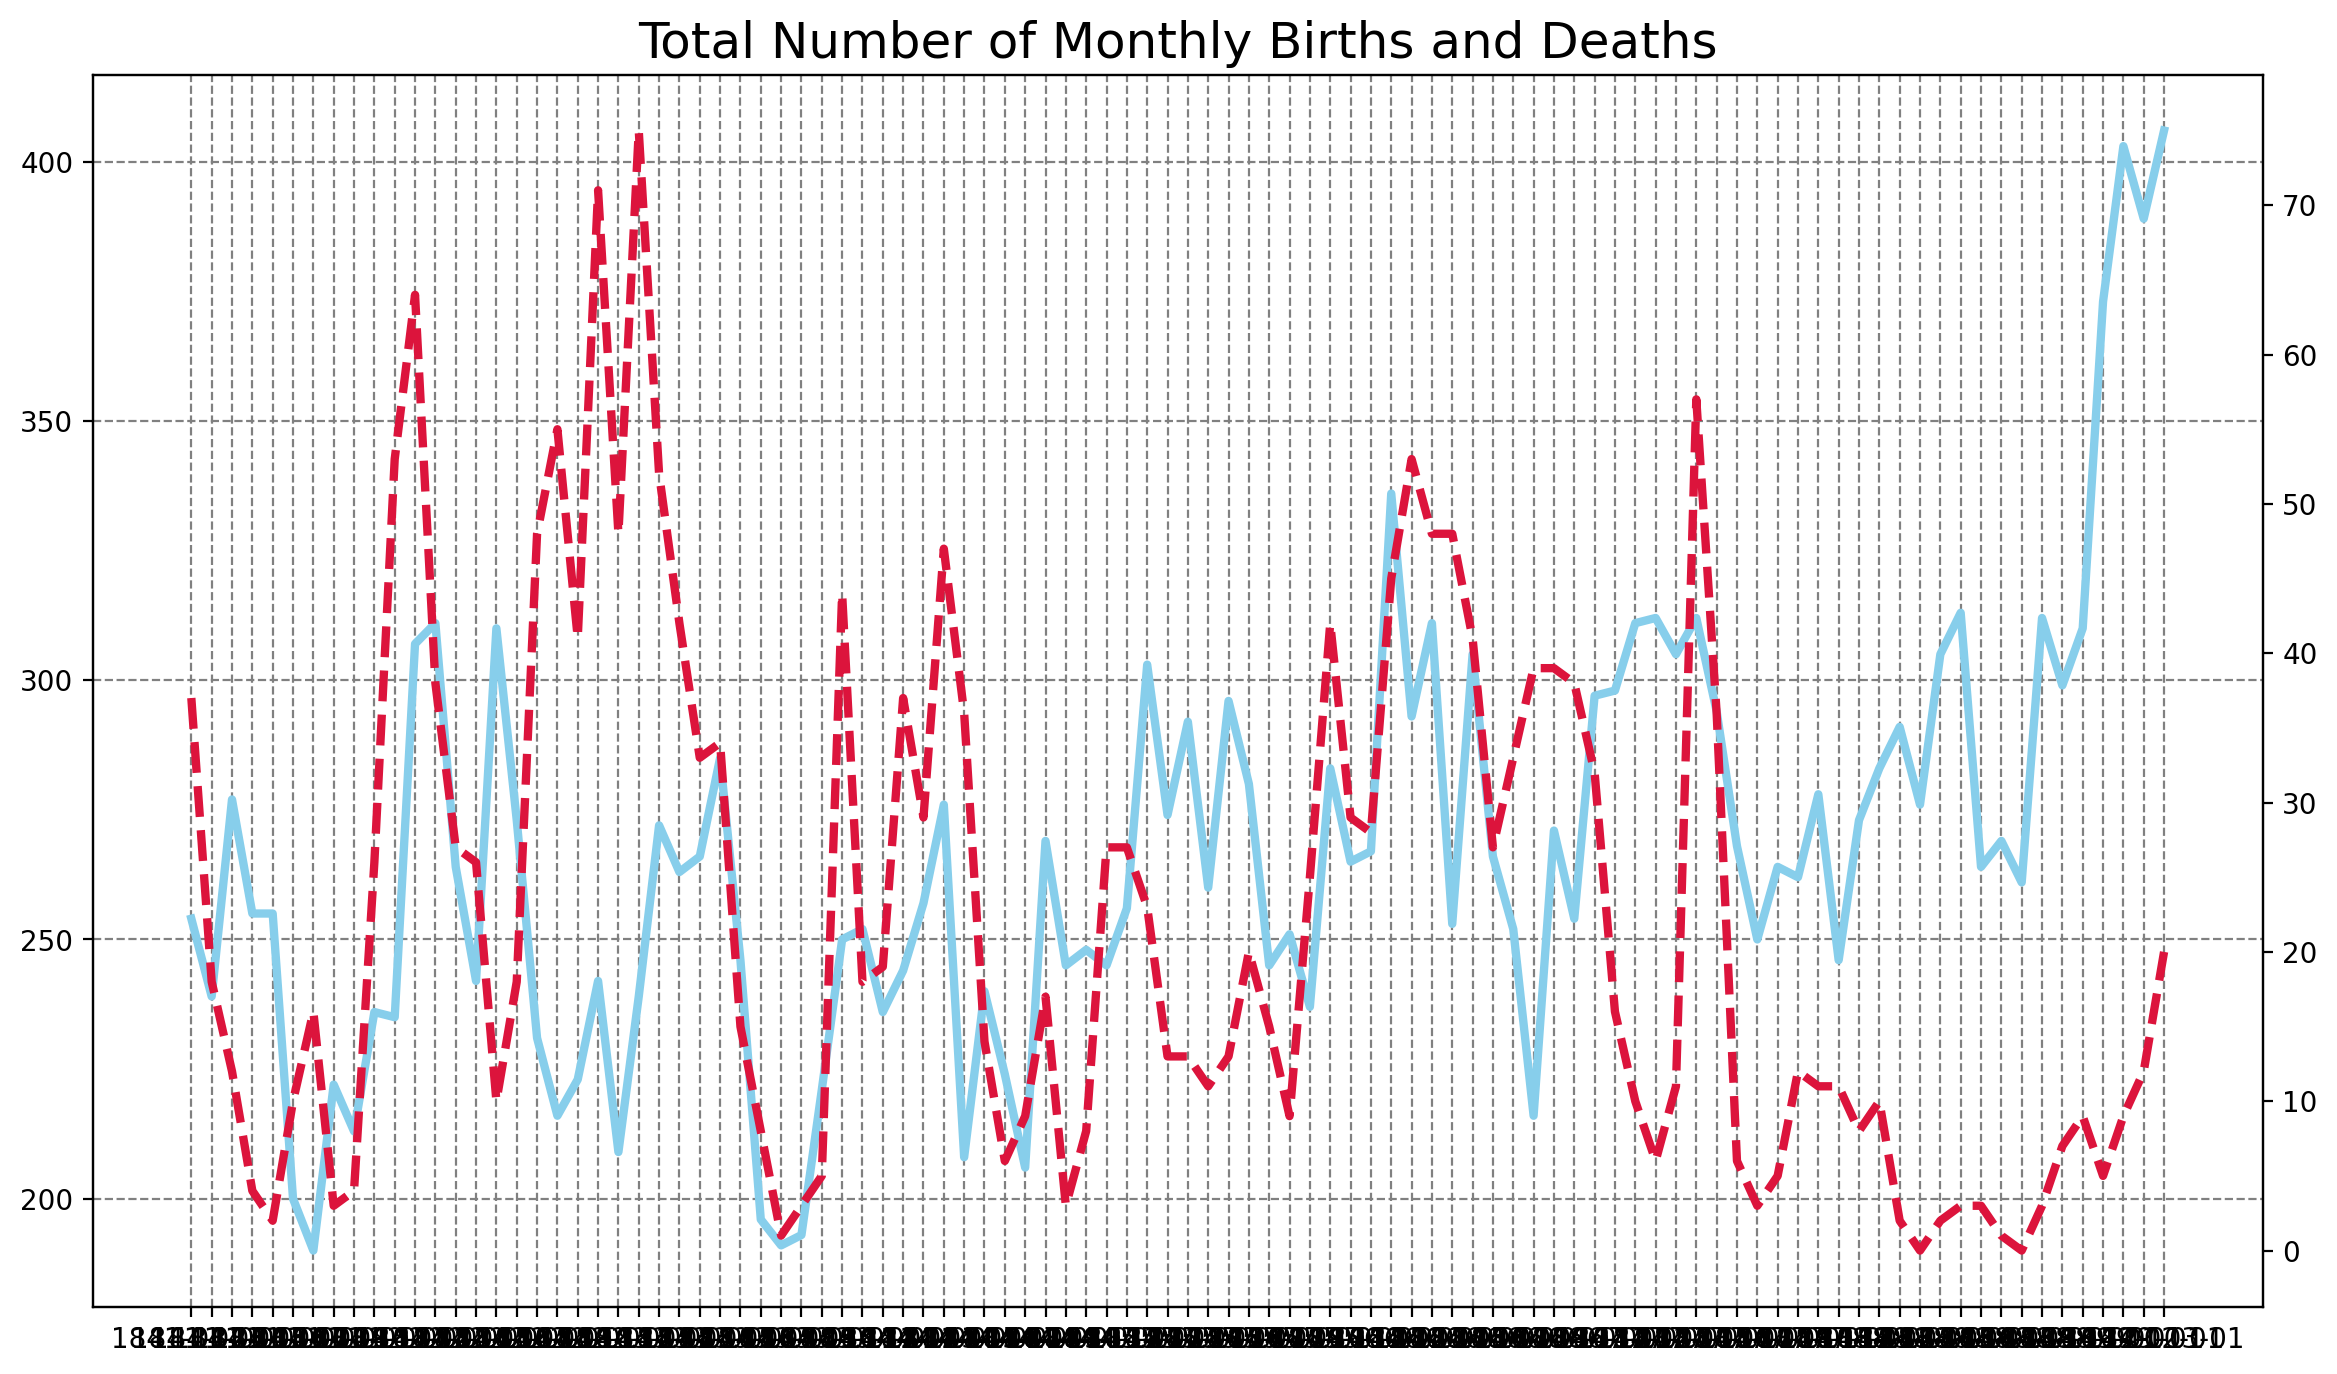

In [ ]:
plt.figure(figsize=(14,8), dpi=200)
plt.title('Total Number of Monthly Births and Deaths', fontsize=18)

ax1 = plt.gca()
ax2 = ax1.twinx()

ax1.grid(color='grey', linestyle='--')

ax1.plot(df_monthly.date,
         df_monthly.births,
         color='skyblue',
         linewidth=3)

ax2.plot(df_monthly.date,
         df_monthly.deaths,
         color='crimson',
         linewidth=3,
         linestyle='--')

plt.show()

In [ ]:
import matplotlib.dates as mdates

In [ ]:
years = mdates. YearLocator()
months = mdates. MonthLocator()
years_fmt = mdates. DateFormatter('%Y')

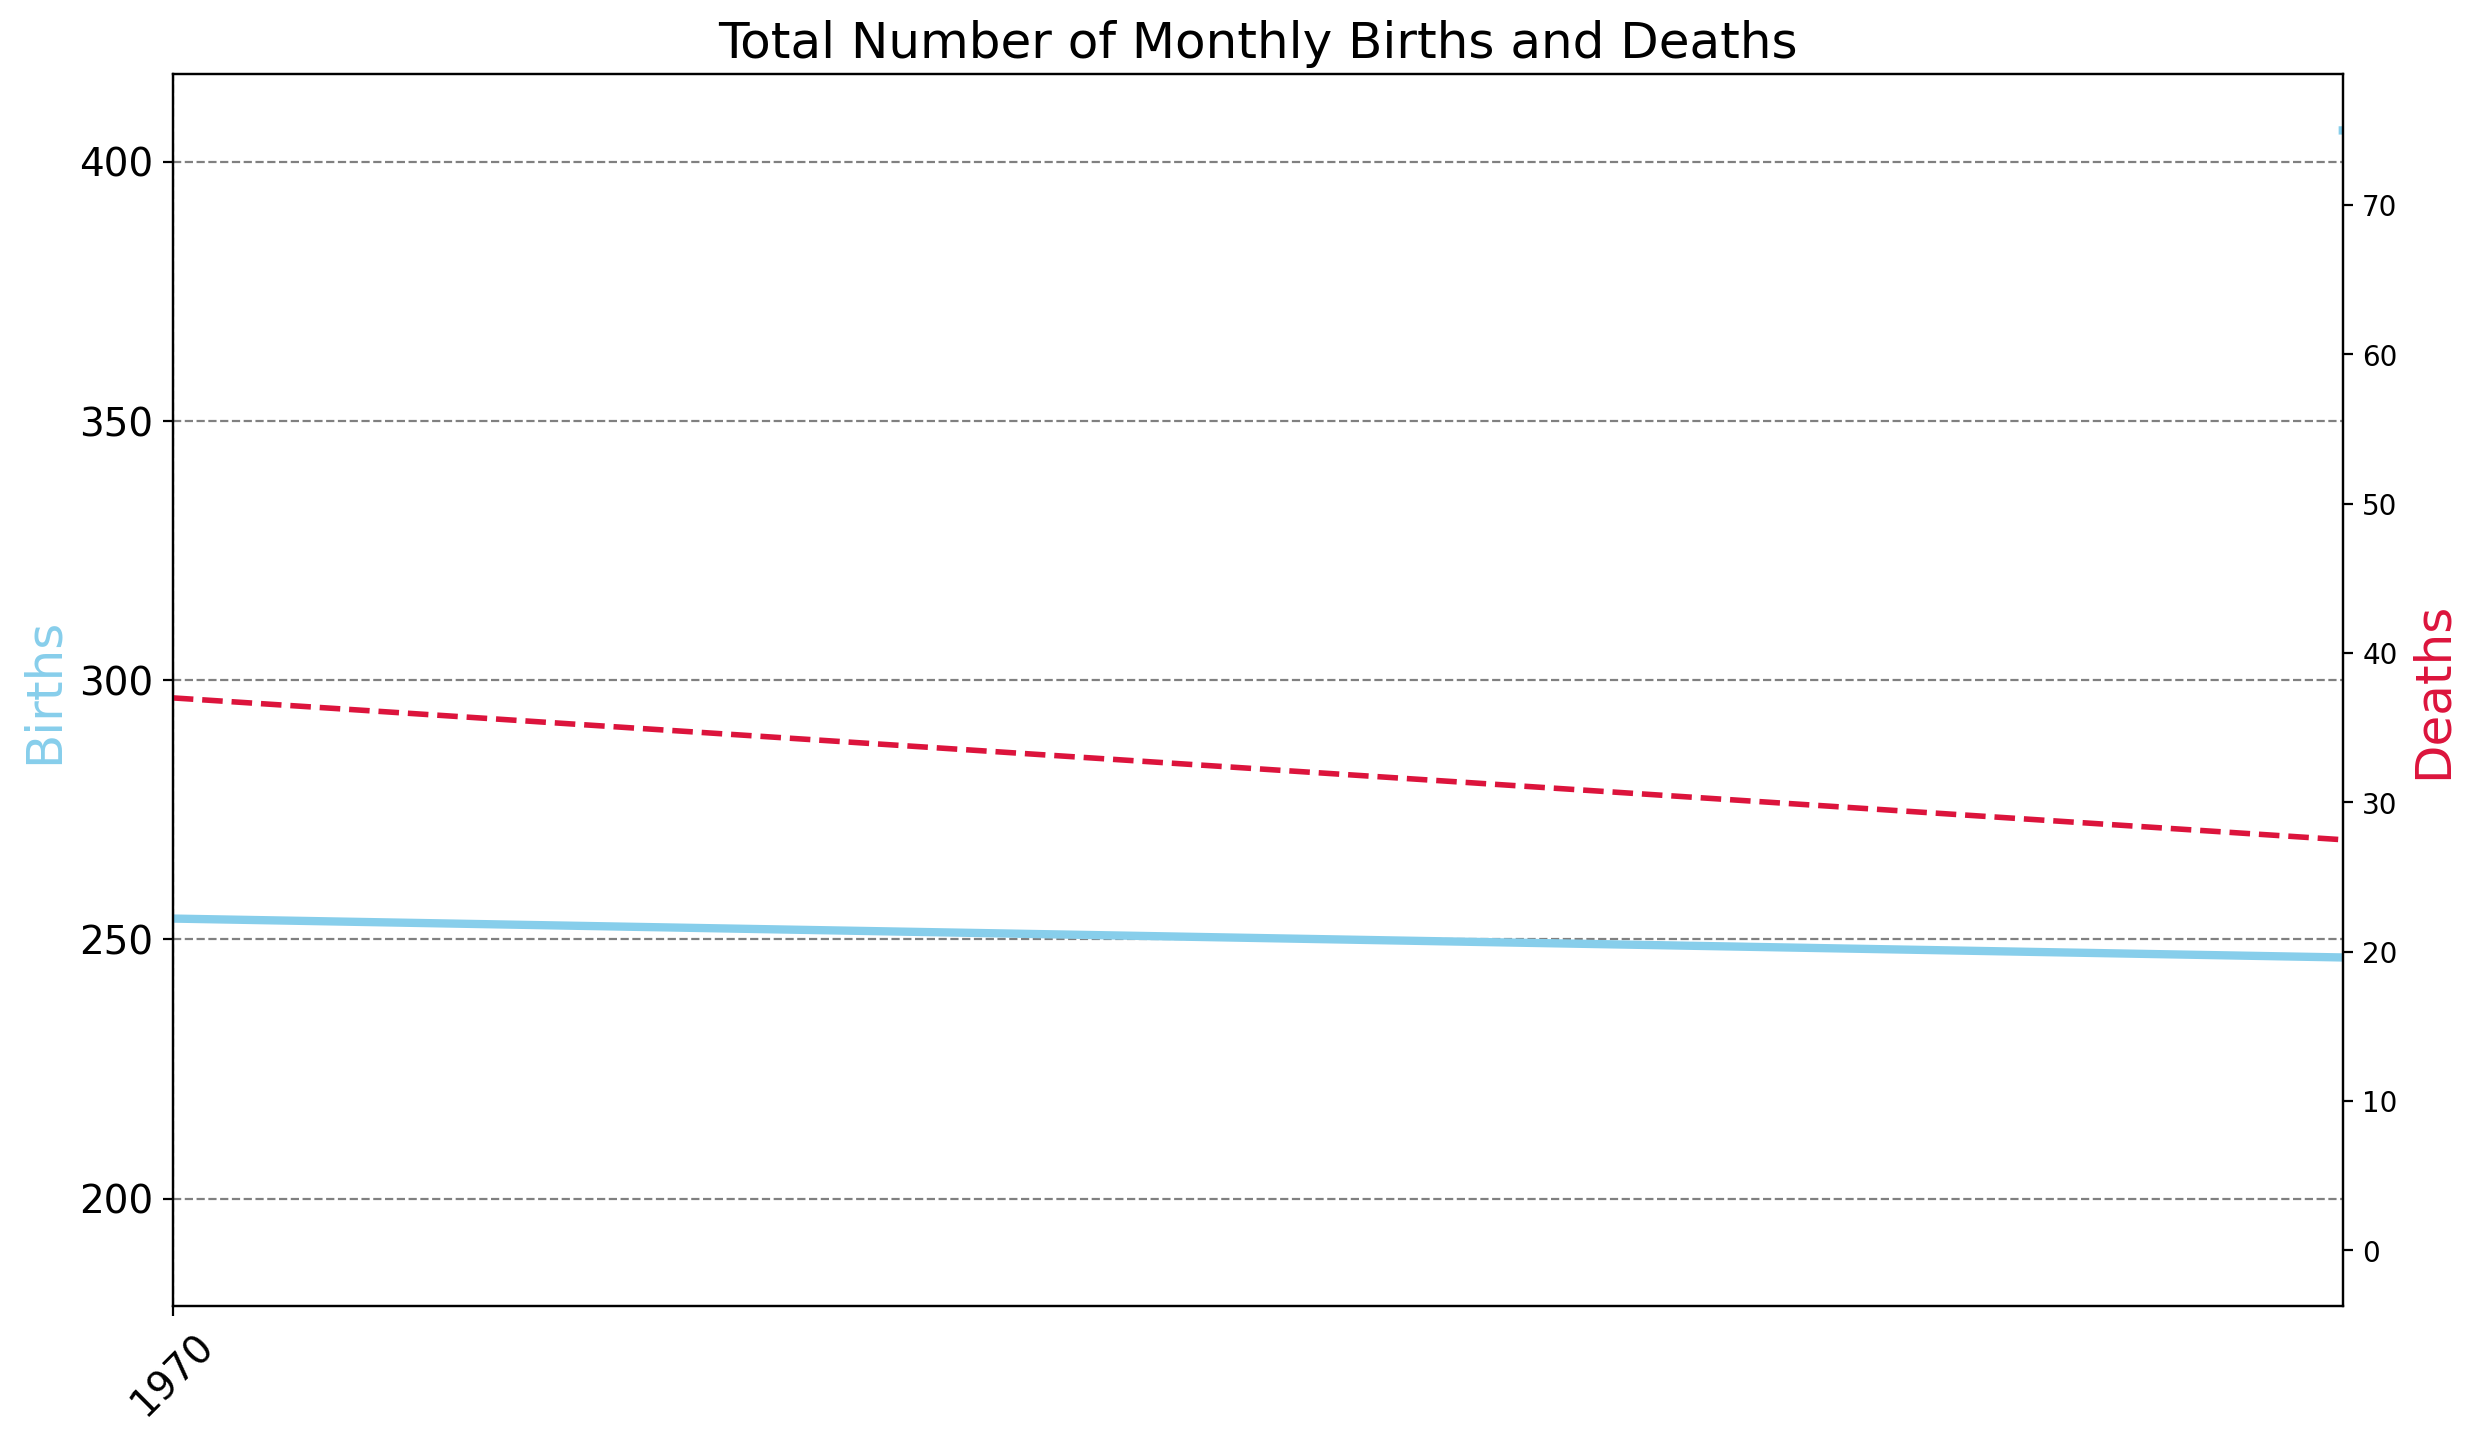

In [ ]:
plt.figure(figsize=(14,8), dpi=200)
plt.title('Total Number of Monthly Births and Deaths', fontsize=18)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14, rotation=45)

ax1 = plt.gca()
ax2 = ax1.twinx()

ax1.set_ylabel('Births', color='skyblue', fontsize=18)
ax2.set_ylabel('Deaths', color='crimson', fontsize=18)

# Use Locators
ax1.set_xlim([df_monthly.date.min(), df_monthly.date.max()])
ax1.xaxis.set_major_locator(years)
ax1.xaxis.set_major_formatter(years_fmt)
ax1.xaxis.set_minor_locator(months)

ax1.grid(color='grey', linestyle='--')

ax1.plot(df_monthly.date,
         df_monthly.births,
         color='skyblue',
         linewidth=3)

ax2.plot(df_monthly.date,
         df_monthly.deaths,
         color='crimson',
         linewidth=2,
         linestyle='--')

plt.show()


In [ ]:
import plotly.express as px

In [ ]:
line = px.line(df_yearly,
               x='year',
               y='births',
               color='clinic',
               title='Total Yearly Births by Clinic')

line.show()

# clinic one is busy

In [ ]:
line = px.line(df_yearly,
               x='year',
               y='deaths',
               color='clinic',
               title='Total Yearly Deaths by Clinic')

line.show()

In [ ]:
df_yearly['pct_deaths'] = df_yearly.deaths / df_yearly.births

In [ ]:
print(df_yearly)

    year  births  deaths    clinic  pct_deaths
0   1841    3036     237  clinic 1    0.078063
1   1842    3287     518  clinic 1    0.157591
2   1843    3060     274  clinic 1    0.089542
3   1844    3157     260  clinic 1    0.082357
4   1845    3492     241  clinic 1    0.069015
5   1846    4010     459  clinic 1    0.114464
6   1841    2442      86  clinic 2    0.035217
7   1842    2659     202  clinic 2    0.075968
8   1843    2739     164  clinic 2    0.059876
9   1844    2956      68  clinic 2    0.023004
10  1845    3241      66  clinic 2    0.020364
11  1846    3754     105  clinic 2    0.027970


In [ ]:
clinic_1 = df_yearly[df_yearly.clinic == 'clinic 1']
avg_c1 = clinic_1.deaths.sum() / clinic_1.births.sum() * 100
print(f'Average death rate in clinic 1 is {avg_c1:.3}%.')

Average death rate in clinic 1 is 9.92%.


In [ ]:
clinic_2 = df_yearly[df_yearly.clinic == 'clinic 2']
avg_c2 = clinic_2.deaths.sum() / clinic_2.births.sum() * 100
print(f'Average death rate in clinic 2 is {avg_c2:.3}%.')

Average death rate in clinic 2 is 3.88%.


In [ ]:
df_monthly['pct_deaths'] = df_monthly.deaths/df_monthly.births

In [ ]:
df_monthly['date'] = pd.to_datetime(df_monthly['date'])
handwashing_start = pd.to_datetime("1847-03-01")

before_washing = df_monthly[df_monthly.date < handwashing_start]
after_washing = df_monthly[df_monthly.date >= handwashing_start]


In [ ]:
bw_rate = before_washing.deaths.sum() / before_washing.births.sum() * 100
aw_rate = after_washing.deaths.sum() / after_washing.births.sum() * 100

In [ ]:
print(f'Average death rate before 1847 was {bw_rate:.4}%')
print(f'Average death rate after 1847 was {aw_rate:.3}%')

Average death rate before 1847 was 10.48%
Average death rate after 1847 was 3.28%


In [ ]:
roll_df = before_washing.set_index('date')
roll_df = roll_df.rolling(window=6).mean()

In [ ]:
print(roll_df)

                births     deaths  pct_deaths
date                                         
1841-01-01         NaN        NaN         NaN
1841-02-01         NaN        NaN         NaN
1841-03-01         NaN        NaN         NaN
1841-04-01         NaN        NaN         NaN
1841-05-01         NaN        NaN         NaN
...                ...        ...         ...
1846-10-01  260.666667  36.166667    0.140159
1846-11-01  259.333333  34.666667    0.135712
1846-12-01  264.666667  32.833333    0.127744
1847-01-01  274.500000  29.000000    0.111277
1847-02-01  290.500000  23.500000    0.084390

[73 rows x 3 columns]


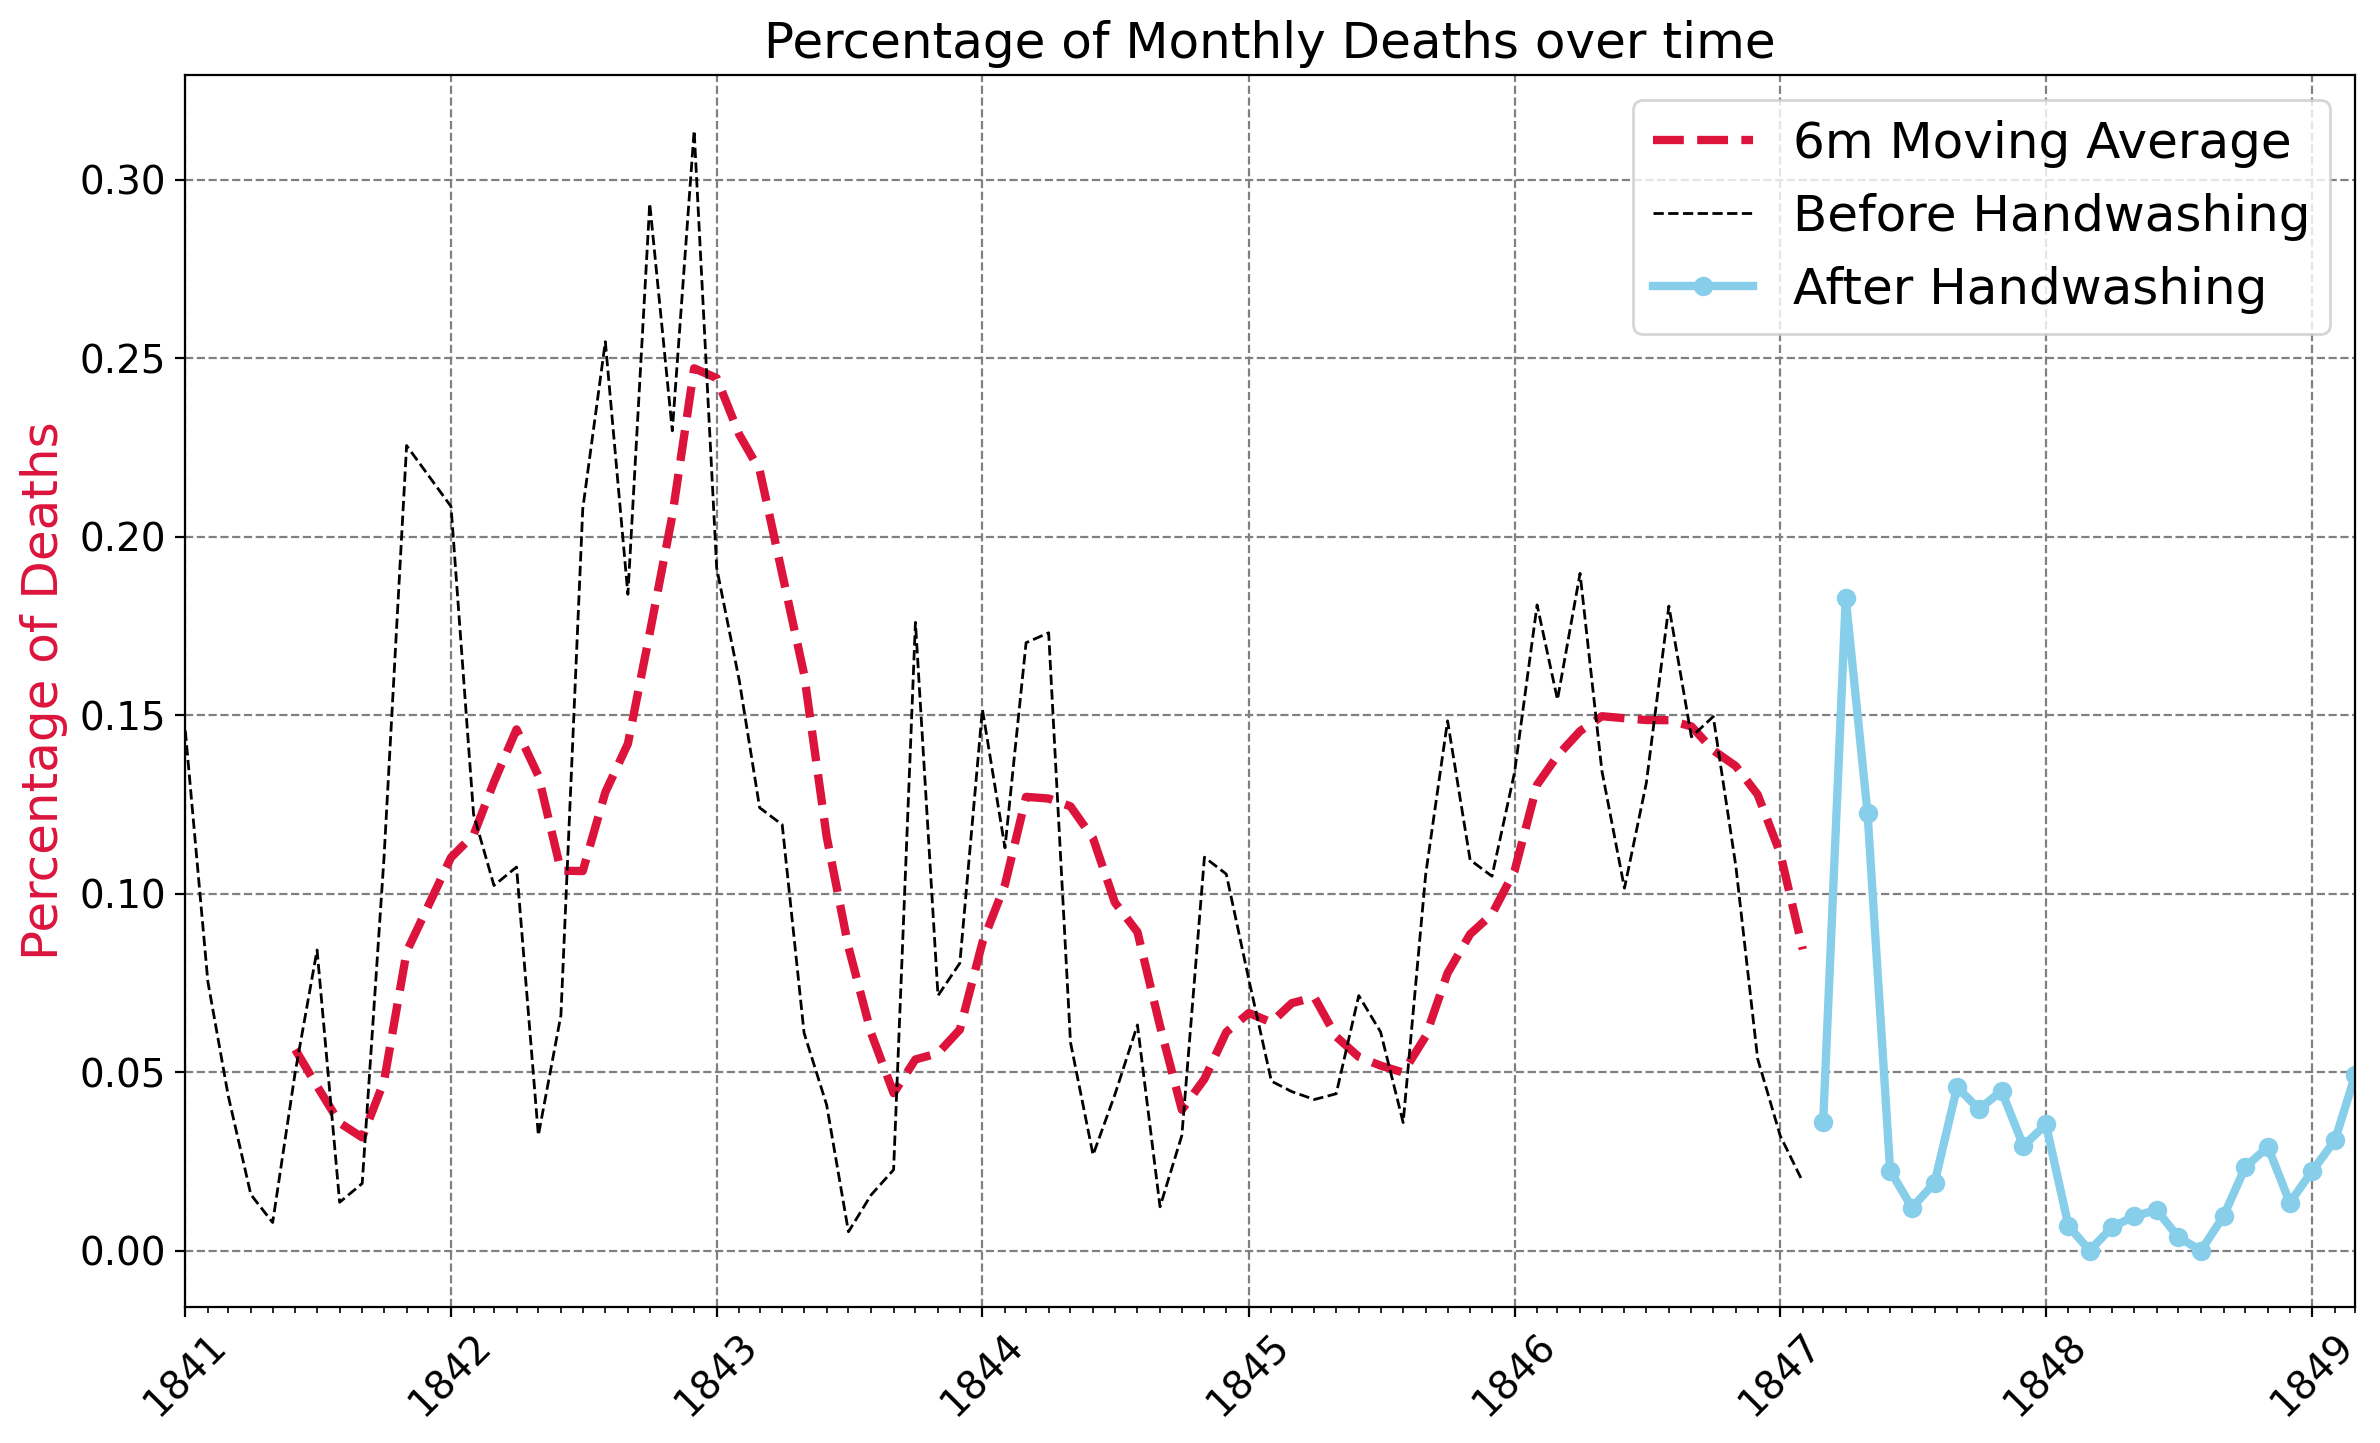

In [ ]:
plt.figure(figsize=(14,8), dpi=200)
plt.title('Percentage of Monthly Deaths over time', fontsize=18)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14, rotation=45)

plt.ylabel('Percentage of Deaths', color='crimson', fontsize=18)

ax = plt.gca()

ax.xaxis.set_major_locator(years)
ax.xaxis.set_major_formatter(years_fmt)
ax.xaxis.set_minor_locator(months)
ax.set_xlim([df_monthly.date.min(), df_monthly.date.max()])

plt.grid(color='grey', linestyle='--')

ma_line, = plt.plot(roll_df.index,
                   roll_df.pct_deaths,
                   color='crimson',
                   linewidth=3,
                   linestyle='--',
                   label = '6m Moving Average')

bw_line, = plt.plot(before_washing.date,
                   before_washing.pct_deaths,
                   color='black',
                   linewidth=1,
                   linestyle='--',
                   label = 'Before Handwashing')

aw_line, = plt.plot(after_washing.date,
                    after_washing.pct_deaths,
                    color='skyblue',
                    linewidth=3,
                    marker='o',
                    label='After Handwashing')



plt.legend(handles=[ma_line, bw_line, aw_line], fontsize=18)

plt.show()

In [ ]:
avg_prob_before = before_washing.pct_deaths.mean() * 100
print(f'Chance of death during childbirth before handwashing: {avg_prob_before:.3}%.')

Chance of death during childbirth before handwashing: 10.5%.


In [ ]:
avg_prob_after = after_washing.pct_deaths.mean() * 100
print(f'Chance of death during childbirth AFTER handwashing: {avg_prob_after:.3}%.')

Chance of death during childbirth AFTER handwashing: 3.22%.


In [ ]:
mean_diff = avg_prob_before - avg_prob_after
print(f'Handwashing reduced the monthly proporation of deaths by {mean_diff:.3}%!')

Handwashing reduced the monthly proporation of deaths by 7.25%!


In [ ]:
times = avg_prob_before / avg_prob_after
print(f'This is a {times:.2}X improvement!')

This is a 3.3X improvement!


In [ ]:
import numpy as np


In [ ]:
df_monthly['washing_hands'] = np.where(df_monthly.date < handwashing_start, 'No', 'Yes')

In [ ]:
box = px.box(df_monthly,
             x='washing_hands',
             y='deaths',
             color='washing_hands',
             title='How Have the Stats Changed with Handwashing?')

box.update_layout(xaxis_title='Washing Hands?')
box.update_layout(yaxis_title='Percentage of Monthlyy Deaths',)

box.show()

In [ ]:
hist = px.histogram(df_monthly,
                    x='pct_deaths',
                    color='washing_hands',
                    nbins=30,
                    opacity=0.6,
                    barmode='overlay',
                    histnorm='percent',
                    marginal='box',)

hist.update_layout(xaxis_title='Proportion of Monthly Deaths',
                   yaxis_title='Count',)

hist.show()

In [ ]:
import seaborn as sns

<ipython-input-74-1c3e4032608e>:3: FutureWarning:



`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.


<ipython-input-74-1c3e4032608e>:4: FutureWarning:



`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.




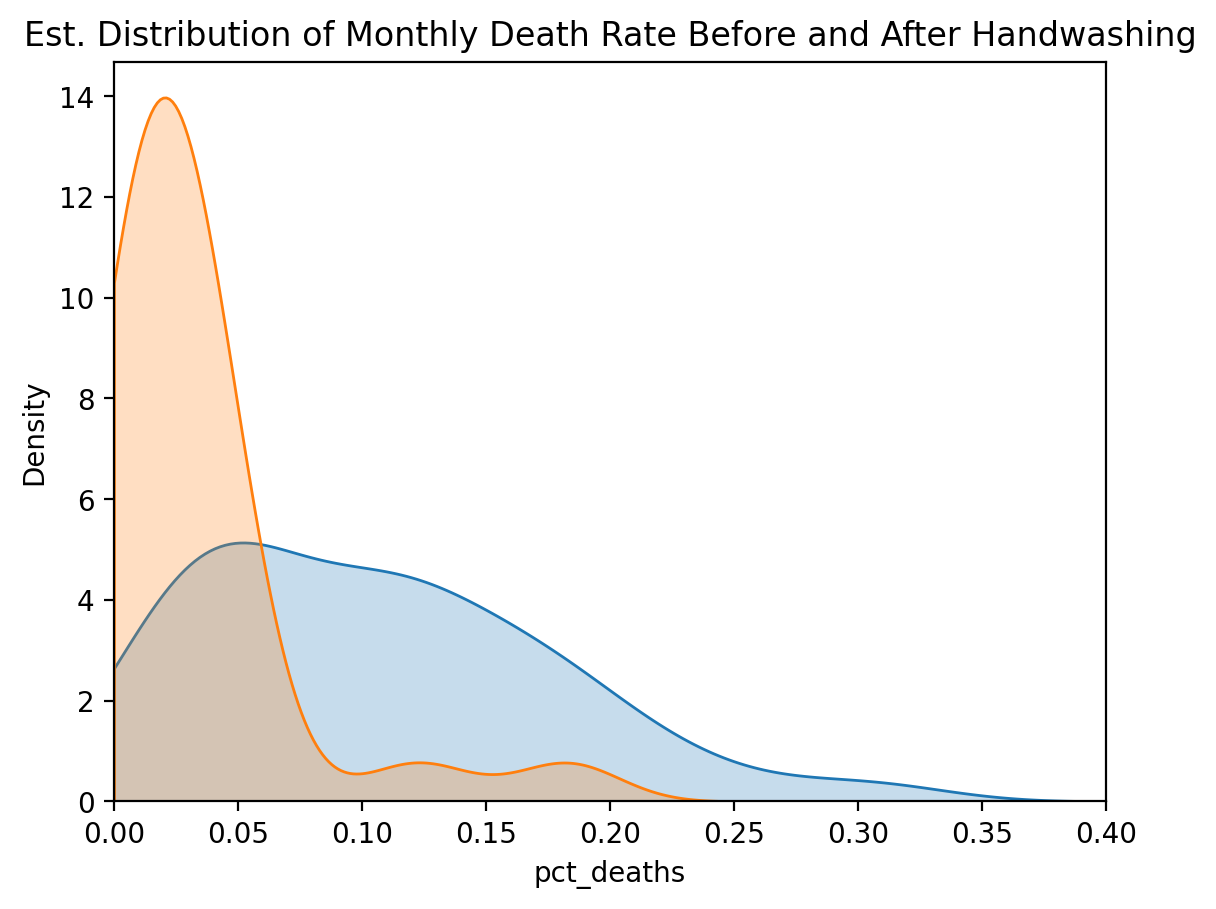

In [ ]:
plt.figure(dpi=200)

sns.kdeplot(before_washing.pct_deaths, shade=True, clip=(0,1))
sns.kdeplot(after_washing.pct_deaths, shade=True, clip=(0,1))

plt.title('Est. Distribution of Monthly Death Rate Before and After Handwashing')

plt.xlim(0, 0.40)

plt.show()

In [ ]:
import scipy.stats as stats


In [ ]:
t_stat, p_value = stats.ttest_ind(a=before_washing.pct_deaths,
                                  b=after_washing.pct_deaths)

print(f'p-palue is {p_value:.10f}')
print(f't-statstic is {t_stat:.4}')

p-palue is 0.0000051428
t-statstic is 4.831
